# ERA5 masked-temperature reconstruction with a Transformer Encoder

This notebook compares a vanilla fully connected autoencoder and Transformer Encoder for reconstructing missing areas in ERA5 2-metre temperature (`t2m`) maps. It also compares both models with a spatial interpolation baseline.

## Data used and meaning of predictions

The ERA5 data is aggregated into daily mean maps on a 41 by 89 grid. The year of each observation is taken from the NetCDF `valid_time` coordinate, not the filename, because some filenames do not match their timestamp years.

### What kind of maps are these, and why are they included?

These are **ERA5 2-metre air-temperature maps**, not satellite images. Each map is a 41 by 89 grid of `t2m` measurements, with each grid cell associated with a latitude and longitude. The notebook combines the time records into one daily mean map. The source temperatures are in Kelvin; the plots convert them to degrees Celsius.

The maps provide the spatial temperature patterns the models learn from. Each daily map is one example for training, validation, or testing. For reconstruction, selected regions are hidden from the model input, and the model estimates the missing temperatures from the visible parts of the map.

The reconstruction figure contains:

- **Original map:** the actual ERA5 temperature map, used as the reference.
- **Masked input:** the same map with selected regions hidden; this is the input to each reconstruction method.
- **Vanilla autoencoder and Transformer Encoder:** their predicted full-map reconstructions. Compare their values in the hidden regions with the original map.
- **Neighbor interpolation:** a simple spatial baseline using the same hidden regions.
- **Hidden-cell error maps:** absolute differences from the original ERA5 values, shown only in the hidden regions; lower errors indicate a closer reconstruction.

The 2024 maps are observed held-out test data. The models reconstruct deliberately hidden cells within those maps; they do not forecast future weather.

### How the data is split

This notebook uses a chronological, year-based split after grouping the source observations into daily maps. The earlier years (2018-2022) are used to fit the model weights. The next year (2023) is kept separate for validation: its masked-cell error guides early stopping and checkpoint selection, not gradient updates. The latest year (2024) is held out for the final reconstruction comparison and is not used to train or select the models. Keeping validation and test years separate from training helps evaluate how the trained models reconstruct maps from later, unseen dates. The table summarizes these roles.

| ERA5 years | Role | What the notebook does |
|---|---|---|
| 2018-2022 | Training | Uses 1,826 daily maps. Random rectangular areas are hidden during training; each model learns to reconstruct the hidden temperature cells from the remaining map. |
| 2023 | Validation | Uses 365 daily maps with fixed hidden areas to track validation error and select the best model checkpoint (early stopping). |
| 2024 | Test and reconstruction | Uses 366 daily maps with fixed hidden areas. The models reconstruct the missing cells, and the predictions are compared with the original ERA5 temperatures at those same cells. |

**This is not a forecast of future weather.** ?Prediction? means estimating the missing portions of an observed 2024 ERA5 map. The original 2024 map is the reference used to evaluate how well those missing cells were reconstructed.

The Transformer follows the structure: an input projection (`inp`), learned positional embedding (`pos`), `TransformerEncoderLayer`, stacked `TransformerEncoder` (`enc`), and prediction head (`head`). Since this task reconstructs a spatial map rather than forecasting one value from the last time step, the head predicts every spatial patch.

Select the project's Python environment/kernel and run all cells in order. The notebook prefers Intel XPU, then NVIDIA CUDA, then CPU. Both learned models use identical data splits and fixed validation and test masks. Training curves, metrics, checkpoints, and geographic plots are saved under `model/`.

In [1]:
%matplotlib inline
from pathlib import Path
import csv
import math

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import h5py
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

def find_project_root(start=Path.cwd()):
    """Find the project root from this notebook's working directory or a parent."""
    for candidate in (start, *start.parents):
        if all((candidate / folder).is_dir() for folder in ("code", "data", "model")):
            return candidate
    raise FileNotFoundError(
        "Could not find the project root above the current working directory. "
        "Open/run this notebook from the cloned project folder."
    )


PROJECT_ROOT = find_project_root()
DATA_DIR = PROJECT_ROOT / "data"
MODEL_DIR = PROJECT_ROOT / "model"
VARIABLE = "t2m"
TRAIN_YEARS = set(range(2018, 2023))
VALIDATION_YEAR = 2023
TEST_YEAR = 2024
SEED = 42
BATCH_SIZE = 32
MAX_EPOCHS = 20
PATIENCE = 5

torch.manual_seed(SEED)
np.random.seed(SEED)
if hasattr(torch, "xpu") and torch.xpu.is_available():
    device = torch.device("xpu")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")
print(f"PyTorch {torch.__version__} | device: {device}")
if device.type == "xpu":
    print(f"Intel GPU: {torch.xpu.get_device_name(0)}")

PyTorch 2.14.1+xpu | device: xpu
Intel GPU: Intel(R) Arc(TM) 140V GPU (16GB)


In [2]:
# Demonstrate why valid_time, not the filename, determines the year.
example_matches = sorted(DATA_DIR.rglob("2020_instant.nc"))
if not example_matches:
    raise FileNotFoundError(f"Example file 2020_instant.nc not found under {DATA_DIR}")
example_file = example_matches[0]
with h5py.File(example_file, "r") as dataset:
    example_times = np.asarray(dataset["valid_time"][:], dtype=np.int64)
if example_times.size == 0:
    raise ValueError(f"{example_file} has no valid_time records.")
example_years = (
    example_times.astype("datetime64[s]").astype("datetime64[Y]").astype(np.int64) + 1970
)
filename_year = int(example_file.stem.split("_")[0])
recorded_years = sorted(set(example_years.tolist()))
print(f"Filename: {example_file.name}")
print(f"Year suggested by filename: {filename_year}")
print(f"Year(s) recorded in valid_time: {', '.join(map(str, recorded_years))}")
print(f"First valid_time: {np.datetime_as_string(np.datetime64(int(example_times.min()), 's'), unit='s')}")
print(f"Last valid_time:  {np.datetime_as_string(np.datetime64(int(example_times.max()), 's'), unit='s')}")
if len(recorded_years) == 1 and filename_year != recorded_years[0]:
    print("Mismatch: use valid_time for the year split, not the filename.")
else:
    print("This sample file's filename year agrees with its valid_time year(s).")

Filename: 2020_instant.nc
Year suggested by filename: 2020
Year(s) recorded in valid_time: 2021
First valid_time: 2021-01-01T00:00:00
Last valid_time:  2021-12-31T21:00:00
Mismatch: use valid_time for the year split, not the filename.


## 1. Load ERA5 and make daily train, validation, and test maps

Dates come from each file's `valid_time` coordinate rather than its filename, because several filenames do not match the years in their timestamps.

In [3]:
instant_files = sorted(DATA_DIR.rglob("*_instant.nc"))
if not instant_files:
    raise FileNotFoundError(
        f"No *_instant.nc files found under {DATA_DIR}. Place the ERA5 *_instant.nc files under data/ERA5/ before running the notebook."
    )

maps_by_split = {"train": [], "validation": [], "test": []}
latitude = None
longitude = None
file_summaries = []

for filename in instant_files:
    with h5py.File(filename, "r") as dataset:
        if VARIABLE not in dataset or "valid_time" not in dataset:
            raise KeyError(f"{filename} is missing {VARIABLE!r} or 'valid_time'.")
        times = np.asarray(dataset["valid_time"][:], dtype=np.int64)
        if not len(times):
            raise ValueError(f"{filename} has no valid_time records.")

        years = (
            times.astype("datetime64[s]").astype("datetime64[Y]").astype(np.int64) + 1970
        )
        day_ids = times // 86400
        unique_days, inverse = np.unique(day_ids, return_inverse=True)
        day_years = (
            unique_days.astype("datetime64[D]").astype("datetime64[Y]").astype(np.int64) + 1970
        )
        frames = np.asarray(dataset[VARIABLE][:], dtype=np.float32)
        current_latitude = np.asarray(dataset["latitude"][:])
        current_longitude = np.asarray(dataset["longitude"][:])
        if latitude is None:
            latitude, longitude = current_latitude, current_longitude
        elif not (
            np.array_equal(latitude, current_latitude)
            and np.array_equal(longitude, current_longitude)
        ):
            raise ValueError(f"Grid coordinates differ in {filename}.")

        daily_maps = np.zeros((len(unique_days), *frames.shape[1:]), dtype=np.float32)
        np.add.at(daily_maps, inverse, frames)
        counts = np.bincount(inverse).astype(np.float32)
        daily_maps /= counts[:, None, None]

        for split_name, selected_years in (
            ("train", TRAIN_YEARS),
            ("validation", {VALIDATION_YEAR}),
            ("test", {TEST_YEAR}),
        ):
            selected = np.isin(day_years, list(selected_years))
            if np.any(selected):
                maps_by_split[split_name].append(daily_maps[selected])
        file_summaries.append(
            (filename.name, int(years.min()), int(years.max()), len(times))
        )

for split_name, arrays in maps_by_split.items():
    if not arrays:
        raise ValueError(f"No {split_name} maps found for the requested years.")
    maps_by_split[split_name] = np.concatenate(arrays, axis=0)
    if not np.isfinite(maps_by_split[split_name]).all():
        raise ValueError(f"{split_name} maps contain non-finite temperature values.")

print("File timestamp coverage (file, first year, last year, records):")
for summary in file_summaries:
    print(summary)
print(f"Grid: {len(latitude)} x {len(longitude)}")
for split_name, maps in maps_by_split.items():
    print(f"{split_name}: {len(maps):,} daily maps; shape {maps.shape[1:]}")

File timestamp coverage (file, first year, last year, records):
('2018_instant.nc', 2018, 2018, 3285)
('2019_instant.nc', 2019, 2019, 3285)
('2020_instant.nc', 2021, 2021, 3285)
('2021_instant.nc', 2020, 2020, 3294)
('2022_instant.nc', 2024, 2024, 3294)
('2023_instant.nc', 2022, 2022, 3285)
('2024_instant.nc', 2023, 2023, 3285)
Grid: 41 x 89
train: 1,826 daily maps; shape (41, 89)
validation: 365 daily maps; shape (41, 89)
test: 366 daily maps; shape (41, 89)


## 2. Vanilla autoencoder and  Transformer Encoder

The vanilla model uses a fully connected encoder/decoder (`encoder` and `decoder`) to map the masked map and its missing-cell indicator to a full-map reconstruction. The Transformer uses the  `inp`/`pos`/`enc`/`head` sequence design. Both predict all grid cells and are trained and evaluated below using the same protocol.

In [4]:
class ERA5Transformer(nn.Module):
   

    def __init__(
        self,
        height,
        width,
        patch_size=4,
        d=64,
        nhead=4,
        nlayers=2,
        d_ff=128,
    ):
        super().__init__()
        self.height = height
        self.width = width
        self.patch_size = patch_size
        self.padded_height = math.ceil(height / patch_size) * patch_size
        self.padded_width = math.ceil(width / patch_size) * patch_size
        self.patch_rows = self.padded_height // patch_size
        self.patch_cols = self.padded_width // patch_size
        self.n_tokens = self.patch_rows * self.patch_cols
        self.patch_area = patch_size * patch_size

        #  pattern: input projection, learned positions, encoder, output head.
        self.inp = nn.Linear(2 * self.patch_area, d)
        self.pos = nn.Embedding(self.n_tokens, d)
        layer = nn.TransformerEncoderLayer(
            d_model=d,
            nhead=nhead,
            dim_feedforward=d_ff,
            dropout=0.1,
            batch_first=True,
        )
        self.enc = nn.TransformerEncoder(layer, num_layers=nlayers)
        self.head = nn.Linear(d, self.patch_area)

    def forward(self, masked_maps, masks):
        # Pad the bottom/right edges to whole patches; padded cells count as missing.
        values = masked_maps.unsqueeze(1)
        missing = masks.unsqueeze(1).to(dtype=values.dtype)
        pad_h = self.padded_height - self.height
        pad_w = self.padded_width - self.width
        values = F.pad(values, (0, pad_w, 0, pad_h))
        missing = F.pad(missing, (0, pad_w, 0, pad_h), value=1.0)

        # [batch, channels * patch area, token] -> [batch, token, features]
        patches = F.unfold(
            torch.cat((values, missing), dim=1),
            kernel_size=self.patch_size,
            stride=self.patch_size,
        ).transpose(1, 2)
        positions = torch.arange(self.n_tokens, device=masked_maps.device)
        tokens = self.inp(patches) + self.pos(positions).unsqueeze(0)
        encoded = self.enc(tokens)

        # Predict every patch (map reconstruction), not only the final token (forecasting).
        patch_values = self.head(encoded).transpose(1, 2)
        reconstruction = F.fold(
            patch_values,
            output_size=(self.padded_height, self.padded_width),
            kernel_size=self.patch_size,
            stride=self.patch_size,
        )
        return reconstruction[:, 0, : self.height, : self.width].flatten(start_dim=1)


grid_shape = maps_by_split["train"].shape[1:]
height, width = grid_shape
train_mean = float(maps_by_split["train"].mean())
train_std = float(maps_by_split["train"].std())
if not np.isfinite(train_std) or train_std == 0:
    raise ValueError("Training maps have invalid or zero temperature standard deviation.")
normalized = {
    split_name: torch.from_numpy(((maps - train_mean) / train_std).astype(np.float32))
    for split_name, maps in maps_by_split.items()
}
train_loader = DataLoader(
    TensorDataset(normalized["train"]), batch_size=BATCH_SIZE, shuffle=True, num_workers=0
)
validation_loader = DataLoader(
    TensorDataset(normalized["validation"]), batch_size=64, shuffle=False, num_workers=0
)
if device.type == "xpu":
    # Release unused cached allocations before placing the model on the Intel GPU.
    torch.xpu.empty_cache()

try:
    model = ERA5Transformer(height, width).to(device)
except RuntimeError as exc:
    message = str(exc).casefold()
    if device.type != "xpu" or not any(
        marker in message
        for marker in ("out_of_device_memory", "out of device memory")
    ):
        raise
    print(
        "Intel GPU ran out of device memory while allocating the Transformer. "
        "Switching this notebook run to CPU; restart the kernel and close GPU-heavy apps to retry XPU."
    )
    device = torch.device("cpu")
    model = ERA5Transformer(height, width).to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)
print(f"Map grid: {grid_shape}; tokens per map: {model.n_tokens}; patch: {model.patch_size} x {model.patch_size}")
print(f"Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

Map grid: (41, 89); tokens per map: 253; patch: 4 x 4
Trainable parameters: 86,288


In [5]:
class VanillaAutoencoder(nn.Module):
    """Fully connected denoising autoencoder for a flattened ERA5 map."""

    def __init__(self, cells):
        super().__init__()
        self.cells = cells
        self.encoder = nn.Sequential(
            nn.Linear(cells * 2, 512),
            nn.ReLU(),
            nn.Linear(512, 128),
            nn.ReLU(),
        )
        self.decoder = nn.Sequential(
            nn.Linear(128, 512),
            nn.ReLU(),
            nn.Linear(512, cells),
        )

    def forward(self, masked_maps, masks):
        values = masked_maps.flatten(start_dim=1)
        missing = masks.flatten(start_dim=1).to(dtype=values.dtype)
        encoded = self.encoder(torch.cat((values, missing), dim=1))
        return self.decoder(encoded)


vanilla_model = VanillaAutoencoder(height * width).to(device)
print(f"Vanilla autoencoder trainable parameters: {sum(p.numel() for p in vanilla_model.parameters() if p.requires_grad):,}")

Vanilla autoencoder trainable parameters: 5,740,737


## 3. Train with validation-based early stopping

Training masks vary each batch. Validation masks are fixed across epochs. The checkpoint with the lowest masked-cell validation MSE is retained.

In [6]:
def make_patch_masks(batch_size, height, width, device, generator):
    """Make two random rectangular hidden patches for each daily map."""
    masks = torch.zeros((batch_size, height, width), dtype=torch.bool, device=device)
    rows = torch.arange(height, device=device)[None, :, None]
    cols = torch.arange(width, device=device)[None, None, :]
    for _ in range(2):
        patch_h = torch.randint(6, 15, (batch_size,), device=device, generator=generator)
        patch_w = torch.randint(12, 29, (batch_size,), device=device, generator=generator)
        top = (
            torch.rand(batch_size, device=device, generator=generator)
            * (height - patch_h + 1)
        ).floor().long()
        left = (
            torch.rand(batch_size, device=device, generator=generator)
            * (width - patch_w + 1)
        ).floor().long()
        masks |= (
            (rows >= top[:, None, None])
            & (rows < (top + patch_h)[:, None, None])
            & (cols >= left[:, None, None])
            & (cols < (left + patch_w)[:, None, None])
        )
    return masks


def evaluate_masked_mse(model, loader, masks):
    model.eval()
    squared_error = 0.0
    hidden_count = 0
    offset = 0
    with torch.no_grad():
        for (targets,) in loader:
            targets = targets.to(device)
            batch_masks = masks[offset : offset + len(targets)]
            offset += len(targets)
            predictions = model(targets.masked_fill(batch_masks, 0.0), batch_masks)
            errors = (predictions - targets.flatten(start_dim=1))[
                batch_masks.flatten(start_dim=1)
            ]
            squared_error += float(errors.square().sum().item())
            hidden_count += errors.numel()
    return squared_error / hidden_count


validation_generator = torch.Generator(device=device).manual_seed(SEED + 1)
validation_masks = make_patch_masks(
    len(normalized["validation"]), height, width, device, validation_generator
)
train_generator = torch.Generator(device=device).manual_seed(SEED + 2)
history = {"train_masked_mse": [], "validation_masked_mse": []}
best_validation = float("inf")
best_state = None
epochs_without_improvement = 0

for epoch in range(MAX_EPOCHS):
    model.train()
    squared_error = 0.0
    hidden_count = 0
    for (targets,) in train_loader:
        targets = targets.to(device)
        masks = make_patch_masks(
            len(targets), height, width, device, train_generator
        )
        predictions = model(targets.masked_fill(masks, 0.0), masks)
        errors = (predictions - targets.flatten(start_dim=1))[
            masks.flatten(start_dim=1)
        ]
        loss = errors.square().mean()
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        squared_error += float(errors.detach().square().sum().item())
        hidden_count += errors.numel()

    train_mse = squared_error / hidden_count
    validation_mse = evaluate_masked_mse(model, validation_loader, validation_masks)
    history["train_masked_mse"].append(train_mse)
    history["validation_masked_mse"].append(validation_mse)
    print(
        f"Epoch {epoch + 1:02d}/{MAX_EPOCHS} | "
        f"train masked MSE: {train_mse:.5f} | "
        f"validation masked MSE: {validation_mse:.5f}"
    )

    if validation_mse < best_validation:
        best_validation = validation_mse
        best_state = {
            key: value.detach().cpu().clone()
            for key, value in model.state_dict().items()
        }
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= PATIENCE:
            print("Early stopping: validation loss did not improve.")
            break

if best_state is None:
    raise RuntimeError("Transformer training did not produce a valid checkpoint.")
model.load_state_dict(best_state)
MODEL_DIR.mkdir(parents=True, exist_ok=True)
MODEL_PATH = MODEL_DIR / "era5_transformer_encoder.pt"
torch.save(
    {
        "model_state_dict": best_state,
        "grid_shape": grid_shape,
        "patch_size": model.patch_size,
        "train_mean": train_mean,
        "train_std": train_std,
        "variable": VARIABLE,
        "best_validation_masked_mse": best_validation,
    },
    MODEL_PATH,
)
print(f"Saved best transformer checkpoint: {MODEL_PATH}")

Epoch 01/20 | train masked MSE: 0.59975 | validation masked MSE: 0.30738
Epoch 02/20 | train masked MSE: 0.28753 | validation masked MSE: 0.23100
Epoch 03/20 | train masked MSE: 0.24187 | validation masked MSE: 0.19007
Epoch 04/20 | train masked MSE: 0.21869 | validation masked MSE: 0.16487
Epoch 05/20 | train masked MSE: 0.20458 | validation masked MSE: 0.15587
Epoch 06/20 | train masked MSE: 0.17617 | validation masked MSE: 0.15007
Epoch 07/20 | train masked MSE: 0.16450 | validation masked MSE: 0.12603
Epoch 08/20 | train masked MSE: 0.15620 | validation masked MSE: 0.12233
Epoch 09/20 | train masked MSE: 0.14324 | validation masked MSE: 0.11317
Epoch 10/20 | train masked MSE: 0.13261 | validation masked MSE: 0.10356
Epoch 11/20 | train masked MSE: 0.11877 | validation masked MSE: 0.10202
Epoch 12/20 | train masked MSE: 0.11427 | validation masked MSE: 0.08469
Epoch 13/20 | train masked MSE: 0.10985 | validation masked MSE: 0.08360
Epoch 14/20 | train masked MSE: 0.10338 | validatio

In [7]:
vanilla_optimizer = torch.optim.AdamW(vanilla_model.parameters(), lr=1e-3, weight_decay=1e-5)
vanilla_train_generator = torch.Generator(device=device).manual_seed(SEED + 4)
vanilla_history = {"train_masked_mse": [], "validation_masked_mse": []}
vanilla_best_validation = float("inf")
vanilla_best_state = None
vanilla_epochs_without_improvement = 0

for epoch in range(MAX_EPOCHS):
    vanilla_model.train()
    squared_error = 0.0
    hidden_count = 0
    for (targets,) in train_loader:
        targets = targets.to(device)
        masks = make_patch_masks(len(targets), height, width, device, vanilla_train_generator)
        predictions = vanilla_model(targets.masked_fill(masks, 0.0), masks)
        errors = (predictions - targets.flatten(start_dim=1))[masks.flatten(start_dim=1)]
        loss = errors.square().mean()
        vanilla_optimizer.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(vanilla_model.parameters(), max_norm=1.0)
        vanilla_optimizer.step()
        squared_error += float(errors.detach().square().sum().item())
        hidden_count += errors.numel()

    vanilla_train_mse = squared_error / hidden_count
    vanilla_validation_mse = evaluate_masked_mse(vanilla_model, validation_loader, validation_masks)
    vanilla_history["train_masked_mse"].append(vanilla_train_mse)
    vanilla_history["validation_masked_mse"].append(vanilla_validation_mse)
    print(
        f"Vanilla AE epoch {epoch + 1:02d}/{MAX_EPOCHS} | "
        f"train masked MSE: {vanilla_train_mse:.5f} | "
        f"validation masked MSE: {vanilla_validation_mse:.5f}"
    )

    if vanilla_validation_mse < vanilla_best_validation:
        vanilla_best_validation = vanilla_validation_mse
        vanilla_best_state = {
            key: value.detach().cpu().clone()
            for key, value in vanilla_model.state_dict().items()
        }
        vanilla_epochs_without_improvement = 0
    else:
        vanilla_epochs_without_improvement += 1
        if vanilla_epochs_without_improvement >= PATIENCE:
            print("Vanilla AE early stopping: validation loss did not improve.")
            break

if vanilla_best_state is None:
    raise RuntimeError("Vanilla autoencoder training did not produce a valid checkpoint.")
vanilla_model.load_state_dict(vanilla_best_state)
VANILLA_MODEL_PATH = MODEL_DIR / "era5_vanilla_autoencoder.pt"
torch.save(
    {
        "model_state_dict": vanilla_best_state,
        "grid_shape": grid_shape,
        "train_mean": train_mean,
        "train_std": train_std,
        "variable": VARIABLE,
        "best_validation_masked_mse": vanilla_best_validation,
    },
    VANILLA_MODEL_PATH,
)
print(f"Saved best vanilla autoencoder checkpoint: {VANILLA_MODEL_PATH}")

Vanilla AE epoch 01/20 | train masked MSE: 0.29088 | validation masked MSE: 0.14644
Vanilla AE epoch 02/20 | train masked MSE: 0.11505 | validation masked MSE: 0.10955
Vanilla AE epoch 03/20 | train masked MSE: 0.11111 | validation masked MSE: 0.08704
Vanilla AE epoch 04/20 | train masked MSE: 0.09092 | validation masked MSE: 0.06582
Vanilla AE epoch 05/20 | train masked MSE: 0.10325 | validation masked MSE: 0.09378
Vanilla AE epoch 06/20 | train masked MSE: 0.08954 | validation masked MSE: 0.06891
Vanilla AE epoch 07/20 | train masked MSE: 0.07441 | validation masked MSE: 0.07730
Vanilla AE epoch 08/20 | train masked MSE: 0.07996 | validation masked MSE: 0.07071
Vanilla AE epoch 09/20 | train masked MSE: 0.08055 | validation masked MSE: 0.05688
Vanilla AE epoch 10/20 | train masked MSE: 0.07261 | validation masked MSE: 0.09389
Vanilla AE epoch 11/20 | train masked MSE: 0.08197 | validation masked MSE: 0.06309
Vanilla AE epoch 12/20 | train masked MSE: 0.07608 | validation masked MSE: 

## 4. Compare both models on held-out 2024 maps

The vanilla autoencoder, Transformer Encoder, and interpolation baseline use the same deterministic 2024 hidden-cell masks. Model checkpoints are selected using validation loss; test errors are measured only on masked cells.

In [8]:
test_generator = torch.Generator(device=device).manual_seed(SEED + 3)
test_masks_torch = make_patch_masks(
    len(normalized["test"]), height, width, device, test_generator
)
test_masks = test_masks_torch.cpu().numpy()
test_targets = maps_by_split["test"]

model.eval()
predictions_normalized = []
with torch.no_grad():
    for start in range(0, len(normalized["test"]), 64):
        targets = normalized["test"][start : start + 64].to(device)
        masks = test_masks_torch[start : start + len(targets)]
        outputs = model(targets.masked_fill(masks, 0.0), masks)
        predictions_normalized.append(outputs.cpu().numpy())
transformer_predictions = (
    np.concatenate(predictions_normalized).reshape((-1, *grid_shape))
    * train_std
    + train_mean
)


def harmonic_inpaint(image, mask, iterations=120):
    """Fill missing cells by iterative averaging of their four neighbors."""
    if image.shape != mask.shape or mask.dtype != np.bool_:
        raise ValueError("image and boolean mask must have the same 2D shape.")
    if not mask.any():
        return image.copy()
    filled = image.astype(np.float32, copy=True)
    filled[mask] = float(image[~mask].mean())
    for _ in range(iterations):
        padded = np.pad(filled, 1, mode="edge")
        neighbor_mean = (
            padded[:-2, 1:-1]
            + padded[2:, 1:-1]
            + padded[1:-1, :-2]
            + padded[1:-1, 2:]
        ) * 0.25
        filled[mask] = neighbor_mean[mask]
    return filled


interpolation_predictions = np.empty_like(test_targets)
for index, (image, mask) in enumerate(zip(test_targets, test_masks)):
    interpolation_predictions[index] = harmonic_inpaint(image, mask)

def masked_metrics(target, prediction, mask):
    errors = prediction[mask] - target[mask]
    return float(np.mean(np.abs(errors))), float(np.sqrt(np.mean(errors**2)))


results = {
    "Transformer Encoder": masked_metrics(
        test_targets, transformer_predictions, test_masks
    ),
    "Neighbor interpolation": masked_metrics(
        test_targets, interpolation_predictions, test_masks
    ),
}
print("2024 held-out metrics on identical hidden cells")
print(f"{'Method':24s} {'MAE (°C)':>12s} {'RMSE (°C)':>12s}")
for method, (mae, rmse) in results.items():
    print(f"{method:24s} {mae:12.3f} {rmse:12.3f}")

with (MODEL_DIR / "era5_transformer_comparison.csv").open(
    "w", newline="", encoding="utf-8"
) as results_file:
    writer = csv.writer(results_file)
    writer.writerow(["method", "mae_celsius", "rmse_celsius"])
    for method, (mae, rmse) in results.items():
        writer.writerow([method, mae, rmse])

2024 held-out metrics on identical hidden cells
Method                       MAE (°C)    RMSE (°C)
Transformer Encoder             0.696        0.927
Neighbor interpolation          0.265        0.489


In [9]:
vanilla_predictions_normalized = []
vanilla_model.eval()
with torch.no_grad():
    for start in range(0, len(normalized["test"]), 64):
        targets = normalized["test"][start : start + 64].to(device)
        masks = test_masks_torch[start : start + len(targets)]
        outputs = vanilla_model(targets.masked_fill(masks, 0.0), masks)
        vanilla_predictions_normalized.append(outputs.cpu().numpy())
vanilla_predictions = (
    np.concatenate(vanilla_predictions_normalized).reshape((-1, *grid_shape))
    * train_std
    + train_mean
)

results["Vanilla autoencoder"] = masked_metrics(
    test_targets, vanilla_predictions, test_masks
)
print("Updated 2024 held-out comparison on identical hidden cells")
print(f"{'Method':24s} {'MAE (?C)':>12s} {'RMSE (?C)':>12s}")
for method, (mae, rmse) in results.items():
    print(f"{method:24s} {mae:12.3f} {rmse:12.3f}")
with (MODEL_DIR / "era5_transformer_comparison.csv").open(
    "w", newline="", encoding="utf-8"
) as results_file:
    writer = csv.writer(results_file)
    writer.writerow(["method", "mae_celsius", "rmse_celsius"])
    for method, (mae, rmse) in results.items():
        writer.writerow([method, mae, rmse])

Updated 2024 held-out comparison on identical hidden cells
Method                       MAE (?C)    RMSE (?C)
Transformer Encoder             0.696        0.927
Neighbor interpolation          0.265        0.489
Vanilla autoencoder             0.565        0.765


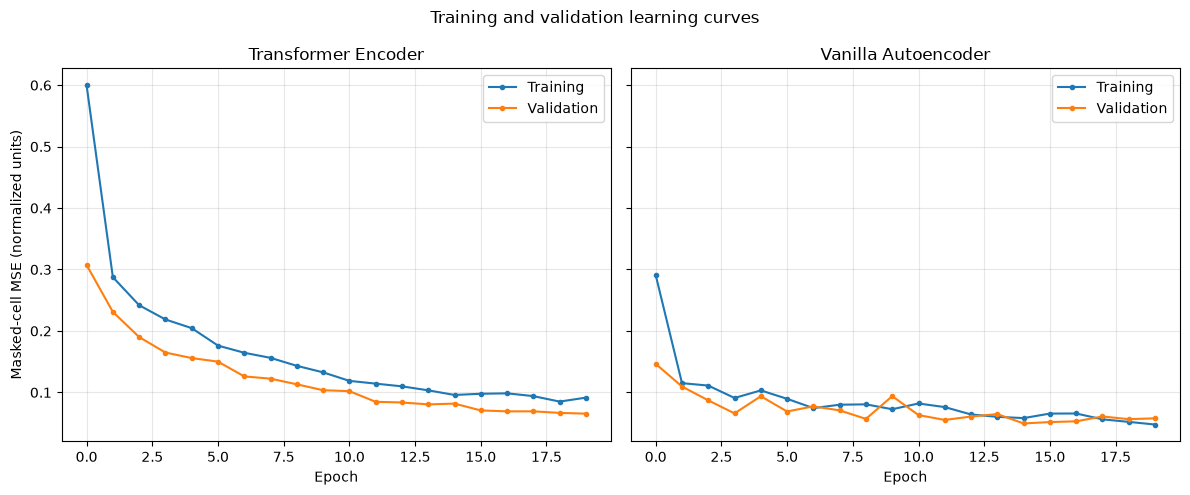

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

axes[0].plot(history["train_masked_mse"], label="Training", marker="o", markersize=3)
axes[0].plot(history["validation_masked_mse"], label="Validation", marker="o", markersize=3)
axes[0].set_title("Transformer Encoder")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Masked-cell MSE (normalized units)")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot(vanilla_history["train_masked_mse"], label="Training", marker="o", markersize=3)
axes[1].plot(vanilla_history["validation_masked_mse"], label="Validation", marker="o", markersize=3)
axes[1].set_title("Vanilla Autoencoder")
axes[1].set_xlabel("Epoch")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

fig.suptitle("Training and validation learning curves")
fig.tight_layout()
fig.savefig(MODEL_DIR / "era5_model_learning_curves.png", dpi=160)
plt.show()

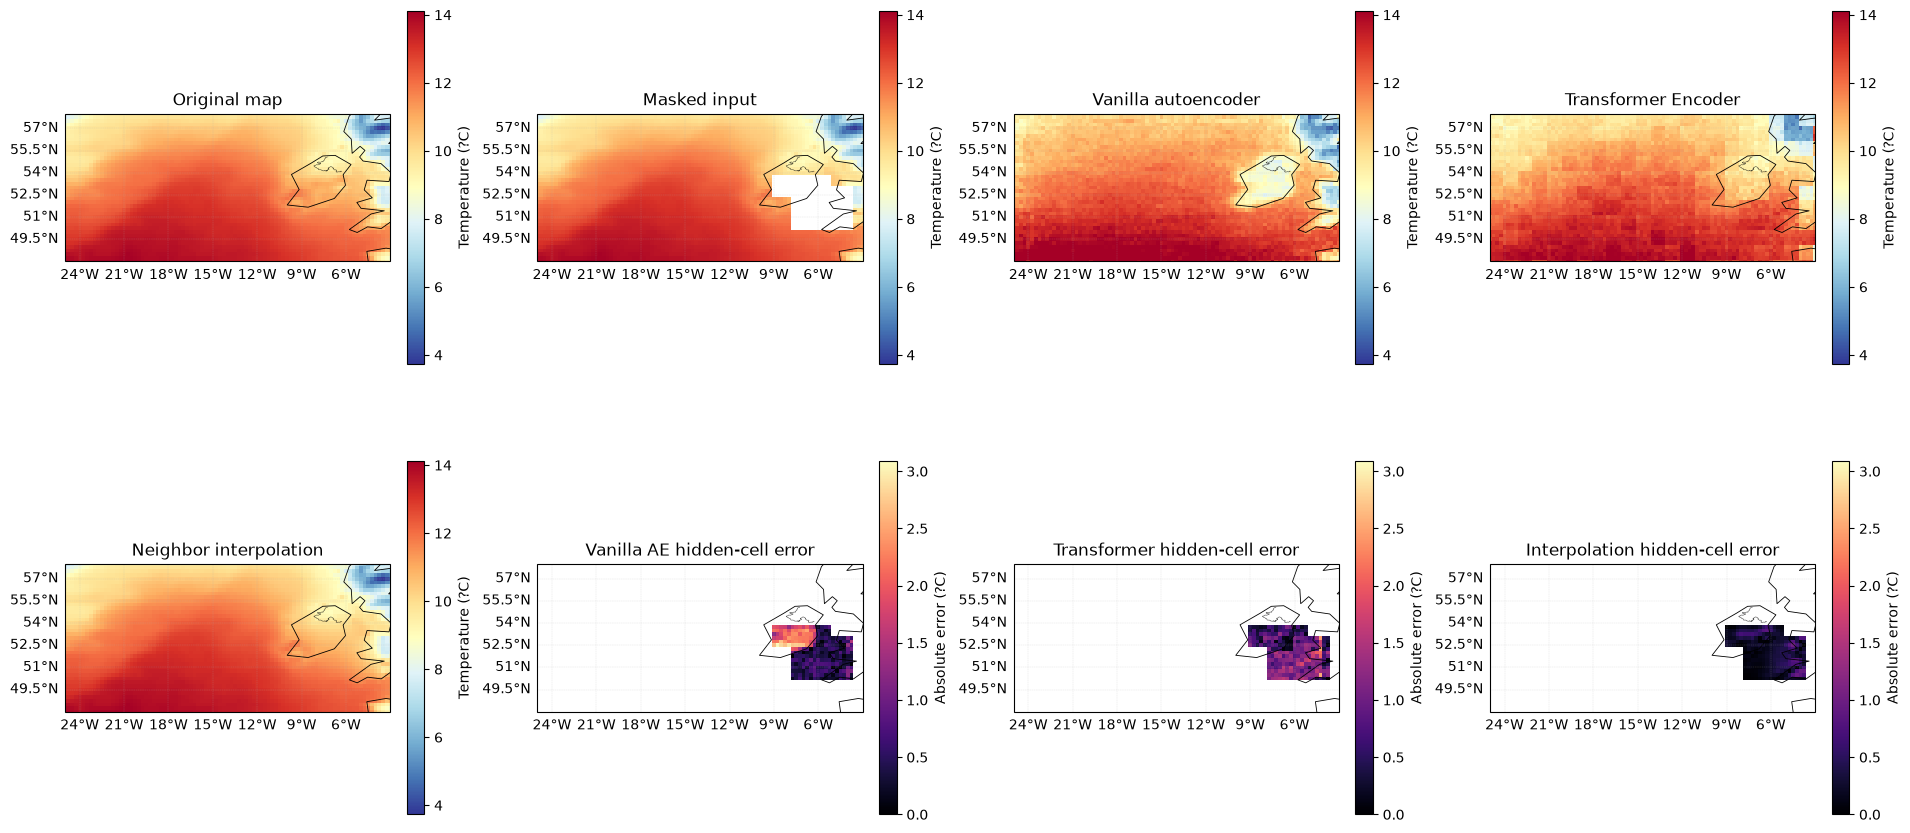

Saved model checkpoints and comparison outputs under d:\PhD\era5_temperature_project\model


In [11]:
sample_index = min(100, len(test_targets) - 1)
target_c = test_targets[sample_index] - 273.15
masked_c = np.where(test_masks[sample_index], np.nan, target_c)
vanilla_c = vanilla_predictions[sample_index] - 273.15
transformer_c = transformer_predictions[sample_index] - 273.15
interpolation_c = interpolation_predictions[sample_index] - 273.15
vanilla_error = np.where(test_masks[sample_index], np.abs(vanilla_c - target_c), np.nan)
transformer_error = np.where(test_masks[sample_index], np.abs(transformer_c - target_c), np.nan)
interpolation_error = np.where(test_masks[sample_index], np.abs(interpolation_c - target_c), np.nan)

fig, axes = plt.subplots(
    2,
    4,
    figsize=(19, 9),
    subplot_kw={"projection": ccrs.PlateCarree()},
    constrained_layout=True,
)
temperature_min = float(np.nanmin(target_c))
temperature_max = float(np.nanmax(target_c))
error_max = max(float(np.nanmax(vanilla_error)), float(np.nanmax(transformer_error)), float(np.nanmax(interpolation_error)))
plots = [
    (target_c, "Original map", "RdYlBu_r", temperature_min, temperature_max, "Temperature (?C)"),
    (masked_c, "Masked input", "RdYlBu_r", temperature_min, temperature_max, "Temperature (?C)"),
    (vanilla_c, "Vanilla autoencoder", "RdYlBu_r", temperature_min, temperature_max, "Temperature (?C)"),
    (transformer_c, "Transformer Encoder", "RdYlBu_r", temperature_min, temperature_max, "Temperature (?C)"),
    (interpolation_c, "Neighbor interpolation", "RdYlBu_r", temperature_min, temperature_max, "Temperature (?C)"),
    (vanilla_error, "Vanilla AE hidden-cell error", "magma", 0, error_max, "Absolute error (?C)"),
    (transformer_error, "Transformer hidden-cell error", "magma", 0, error_max, "Absolute error (?C)"),
    (interpolation_error, "Interpolation hidden-cell error", "magma", 0, error_max, "Absolute error (?C)"),
]
for ax, (field, title, cmap, vmin, vmax, colorbar_label) in zip(axes.flat, plots):
    image = ax.pcolormesh(
        longitude, latitude, field, shading="auto", cmap=cmap, vmin=vmin, vmax=vmax
    )
    ax.set_extent(
        [longitude.min(), longitude.max(), latitude.min(), latitude.max()],
        crs=ccrs.PlateCarree(),
    )
    ax.coastlines(resolution="110m", linewidth=0.6)
    ax.add_feature(cfeature.BORDERS, linewidth=0.4, alpha=0.7)
    gridlines = ax.gridlines(draw_labels=True, linewidth=0.3, alpha=0.4, linestyle="--")
    gridlines.top_labels = False
    gridlines.right_labels = False
    ax.set_title(title)
    fig.colorbar(image, ax=ax, shrink=0.8, label=colorbar_label)
fig.savefig(MODEL_DIR / "era5_model_reconstruction_comparison.png", dpi=160)
plt.show()
print(f"Saved model checkpoints and comparison outputs under {MODEL_DIR}")

## 5. Interpret the results

### What is the input and what are the predictions?

- **Original map** is the reference ERA5 daily 2-metre temperature field for one held-out 2024 day. It is shown in degrees Celsius.
- **Masked input** is that same map after selected rectangular areas have been hidden. Blank areas are the missing cells supplied to the models; visible areas are the observed input.
- **Vanilla autoencoder**, **Transformer Encoder**, and **Neighbor interpolation** are three full-map reconstructions from that masked input. Compare their values inside the hidden rectangles against the corresponding areas in **Original map**. The models also output estimates at visible cells, but those cells were not hidden and are not the target of the reported test scores.
- The three **hidden-cell error** panels show absolute temperature difference from the original, only where cells were hidden. Darker/lower values mean smaller error; the colorbar is in degrees Celsius.

### How to read the scores

The printed table and `era5_transformer_comparison.csv` report metrics only over hidden cells from the held-out 2024 maps. **MAE** is the average absolute error in degrees Celsius; **RMSE** is the square root of the average squared error and gives larger mistakes more influence. Lower values are better. Compare both learned models with interpolation: a model is useful if it reduces error on the same hidden cells. These are held-out test results, not training or validation scores.

### How to read the learning curves

Each panel has the model's training and validation masked-cell MSE (in normalized units) over epochs. Decreasing curves indicate improving reconstruction on their respective data. If training continues to improve while validation stops improving or rises, that can indicate overfitting; the saved checkpoint is selected using the best validation loss. Small gaps or a validation curve below training are not, by themselves, proof of a problem.

The map panel shows one test day (`sample_index`), while the table summarizes all 2024 test maps. Use the table for overall comparison and the maps for a visual example; one day may not represent every day or weather situation.